# Estudos de exercício concluídos

Cortes da camada gold: 26.476 ensaios clínicos concluídos cuja intervenção testada é exercício. Um estudo pode entrar em mais de um grupo. As listas são abertas no DuckDB e a contagem é de estudo distinto.


In [8]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data" / "clinical_trials.duckdb").exists():
    ROOT = ROOT.parent
DB_PATH = ROOT / "data" / "clinical_trials.duckdb"

con = duckdb.connect(str(DB_PATH), read_only=True)

ROTULOS_GRUPO = {
    "exercicio": "Exercício",
    "forca": "Força",
    "mobilidade": "Mobilidade",
    "aerobico": "Aeróbico",
    "fisioterapia": "Fisioterapia",
    "reabilitacao": "Reabilitação",
    "esporte": "Esporte",
    "pilates": "Pilates",
}


def consultar(sql: str) -> pd.DataFrame:
    return con.execute(sql).fetchdf()


def barras(df: pd.DataFrame, titulo: str, xlabel: str) -> None:
    plot = df.iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, max(3.2, 0.38 * len(plot))))
    ax.barh(plot.iloc[:, 0].astype(str), plot.iloc[:, 1])
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(df.columns[0])
    fig.tight_layout()
    plt.show()


total = consultar("SELECT count(*) AS estudos FROM gold.estudos").iloc[0, 0]
print(f"{total} estudos na gold")


12158 estudos na gold


In [9]:
primeiras = consultar(
    """
    SELECT *
    FROM gold.estudos
    ORDER BY nct_id
    LIMIT 5
    """
)
ultimas = consultar(
    """
    SELECT *
    FROM gold.estudos
    ORDER BY nct_id DESC
    LIMIT 5
    """
)
display(primeiras)
display(ultimas.iloc[::-1].reset_index(drop=True))


,nct_id,brief_title,official_title,brief_summary,study_type,phase,phases,overall_status,start_date,completion_date,...,gender,conditions,interventions,mesh_terms,countries_current,lead_sponsors,were_results_reported,termos_encontrados,url,_gold_at
0,NCT00000399,Bone Estrogen Strength Training,Bone Estrogen Strength Training (BEST),"We started the Bone, Estrogen, Strength Traini...",INTERVENTIONAL,PHASE2,[PHASE2],COMPLETED,1995-08-31,2001-01-31,...,FEMALE,"[{'name': 'Osteoporosis', 'name_normalized': '...","[{'intervention_type': 'DRUG', 'name': 'Hormon...","[{'mesh_term': 'Bone Diseases, Metabolic', 'me...","[{'name': 'United States', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[forca],https://clinicaltrials.gov/study/NCT00000399,2026-10-13 22:54:05.562924-03:00
1,NCT00000409,Spine Patient Outcomes Research Trial (SPORT):...,Spine Patient Outcomes Research Trial (SPORT):...,This study tests the effectiveness of differen...,INTERVENTIONAL,PHASE4,[PHASE4],COMPLETED,2000-03-31,2015-04-30,...,ALL,"[{'name': 'Spondylolisthesis', 'name_normalize...","[{'intervention_type': 'PROCEDURE', 'name': 'D...","[{'mesh_term': 'Spondylolysis', 'mesh_type': '...","[{'name': 'United States', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[fisioterapia],https://clinicaltrials.gov/study/NCT00000409,2026-10-13 22:54:05.562924-03:00
2,NCT00000410,Spine Patient Outcomes Research Trial (SPORT) ...,Spine Patient Outcomes Research Trial (SPORT):...,This study tests the effectiveness of differen...,INTERVENTIONAL,PHASE4,[PHASE4],COMPLETED,2000-03-31,2015-04-30,...,ALL,"[{'name': 'Herniated Disc', 'name_normalized':...","[{'intervention_type': 'PROCEDURE', 'name': 'D...","[{'mesh_term': 'Spinal Diseases', 'mesh_type':...","[{'name': 'United States', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,"[mobilidade, fisioterapia]",https://clinicaltrials.gov/study/NCT00000410,2026-10-13 22:54:05.562924-03:00
3,NCT00000411,Spine Patient Outcomes Research Trial (SPORT):...,Spine Patient Outcomes Research Trial (SPORT):...,This study tests the effectiveness of differen...,INTERVENTIONAL,PHASE4,[PHASE4],COMPLETED,2000-03-31,2015-04-30,...,ALL,"[{'name': 'Spinal Stenosis', 'name_normalized'...","[{'intervention_type': 'PROCEDURE', 'name': 'D...","[{'mesh_term': 'Spinal Diseases', 'mesh_type':...","[{'name': 'United States', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[fisioterapia],https://clinicaltrials.gov/study/NCT00000411,2026-10-13 22:54:05.562924-03:00
4,NCT00000434,Impact of Exercise on Older Persons With Osteo...,Impact of Exercise on Older Persons With Osteo...,Previous studies have found that exercise can ...,INTERVENTIONAL,PHASE2,[PHASE2],COMPLETED,1983-12-31,2003-09-30,...,ALL,"[{'name': 'Osteoarthritis', 'name_normalized':...","[{'intervention_type': 'BEHAVIORAL', 'name': '...","[{'mesh_term': 'Arthritis', 'mesh_type': 'mesh...","[{'name': 'United States', 'removed': False}]","[{'agency_class': 'NIH', 'lead_or_collaborator...",False,"[mobilidade, forca]",https://clinicaltrials.gov/study/NCT00000434,2026-10-13 22:54:05.562924-03:00


,nct_id,brief_title,official_title,brief_summary,study_type,phase,phases,overall_status,start_date,completion_date,...,gender,conditions,interventions,mesh_terms,countries_current,lead_sponsors,were_results_reported,termos_encontrados,url,_gold_at
0,NCT07811284,Effects of Mechanical Massage on Sleep Quality...,Impact of a Multisession LPG Cellu M6 Alliance...,"This bicentric, randomized, single-blind clini...",INTERVENTIONAL,NA,[NA],COMPLETED,2023-01-12,2023-06-14,...,ALL,"[{'name': 'Stress (Psychology)', 'name_normali...","[{'intervention_type': 'DEVICE', 'name': 'Mech...",[],"[{'name': 'France', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[mobilidade],https://clinicaltrials.gov/study/NCT07811284,2026-10-13 22:54:05.562924-03:00
1,NCT07812909,Effects of Sprinter and Skater on Text Neck Sy...,Combined Effects of Sprinter and Skater Synerg...,This study will explore the combined effects o...,INTERVENTIONAL,NA,[NA],COMPLETED,2026-04-24,2026-08-09,...,ALL,"[{'name': 'Text Neck Syndrome', 'name_normaliz...","[{'intervention_type': 'OTHER', 'name': 'Coord...",[],"[{'name': 'Pakistan', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[forca],https://clinicaltrials.gov/study/NCT07812909,2026-10-13 22:54:05.562924-03:00
2,NCT07814040,Play Based Approach Among Autism,Effectiveness of the B.A.S.I.C.S. Framework as...,This pilot study evaluates the effectiveness o...,INTERVENTIONAL,NA,[NA],COMPLETED,2026-01-03,2026-07-30,...,ALL,"[{'name': 'Autism Spectrum Disorder', 'name_no...","[{'intervention_type': 'BEHAVIORAL', 'name': '...","[{'mesh_term': 'Child Development Disorders, P...","[{'name': 'India', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,"[mobilidade, fisioterapia]",https://clinicaltrials.gov/study/NCT07814040,2026-10-13 22:54:05.562924-03:00
3,NCT07814846,Effect of Pre-operative Program in Open Heart ...,Effect of Pre-operative Multimedia Physical Th...,The goal of this clinical trial is to learn th...,INTERVENTIONAL,NA,[NA],COMPLETED,2020-12-17,2023-12-31,...,ALL,"[{'name': 'Cardio Vascular Disease', 'name_nor...","[{'intervention_type': 'OTHER', 'name': 'Multi...",[],"[{'name': 'Thailand', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,"[mobilidade, fisioterapia]",https://clinicaltrials.gov/study/NCT07814846,2026-10-13 22:54:05.562924-03:00
4,NCT07816419,Yogic Eye Exercises for Computer Vision Syndro...,Effect of a Four-Week Yogic Eye Exercise Progr...,Computer vision syndrome (CVS) is a cluster of...,INTERVENTIONAL,NA,[NA],COMPLETED,2021-03-15,2021-04-16,...,FEMALE,[{'name': 'Computer Vision Syndrome · Asthenop...,"[{'intervention_type': 'BEHAVIORAL', 'name': '...",[],"[{'name': 'Saudi Arabia', 'removed': False}]","[{'agency_class': 'OTHER', 'lead_or_collaborat...",False,[forca],https://clinicaltrials.gov/study/NCT07816419,2026-10-13 22:54:05.562924-03:00


In [10]:
primeiras_referencias = consultar(
    """
    SELECT *
    FROM gold.referencias
    ORDER BY nct_id, pmid
    LIMIT 5
    """
)
ultimas_referencias = consultar(
    """
    SELECT *
    FROM gold.referencias
    ORDER BY nct_id DESC, pmid DESC
    LIMIT 5
    """
)
display(primeiras_referencias)
display(ultimas_referencias.iloc[::-1].reset_index(drop=True))


,nct_id,pmid,reference_type,citation,titulo,periodico,ano,resumo,busca_status
0,NCT00000399,14608080,BACKGROUND,"Harris MM, Houtkooper LB, Stanford VA, Parkhil...",Dietary iron is associated with bone mineral d...,The Journal of nutrition,2003,Healthy nonsmoking postmenopausal women (n = 2...,ok
1,NCT00000399,25785226,DERIVED,"Harris M, Farrell V, Houtkooper L, Going S, Lo...",Associations of polyunsaturated Fatty Acid int...,Journal of osteoporosis,2015,A secondary analysis of cross-sectional data w...,ok
2,NCT00000409,10787504,BACKGROUND,"Weinstein JN, Brown PW, Hanscom B, Walsh T, Ne...",Designing an ambulatory clinical practice for ...,Quality management in health care,2000,Development of a new program for diagnosis and...,ok
3,NCT00000409,12065987,BACKGROUND,"Birkmeyer NJ, Weinstein JN, Tosteson AN, Toste...",Design of the Spine Patient outcomes Research ...,Spine,2002,SUMMARY OF BACKGROUND DATA: The Spine Patient ...,ok
4,NCT00000409,12642770,BACKGROUND,"Walsh TL, Hanscom B, Lurie JD, Weinstein JN. I...",Is a condition-specific instrument for patient...,Spine,2003,STUDY DESIGN: Analysis of longitudinal data co...,ok


,nct_id,pmid,reference_type,citation,titulo,periodico,ano,resumo,busca_status
0,NCT07812909,39275600,BACKGROUND,"Almeida MB, Moreira M, Miranda-Oliveira P, Mor...",Evolving Dynamics of Neck Muscle Activation Pa...,"Sensors (Basel, Switzerland)",2024,Cervical pain has been linked to increased mot...,ok
1,NCT07812909,40004916,BACKGROUND,"Piruta J, Kulak W. Physiotherapy in Text Neck ...",Physiotherapy in Text Neck Syndrome: A Scoping...,Journal of clinical medicine,2025,Background: Musculoskeletal disorders associat...,ok
2,NCT07812909,41263915,BACKGROUND,"Xu Y, Feng M, Wu R, Wang Y, Yang Z, Wang Z, Ka...",Effect of adding proprioceptive neuromuscular ...,BMJ open,2025,INTRODUCTION: Adolescent idiopathic scoliosis ...,ok
3,NCT07812909,41316601,BACKGROUND,"Binaei F, Kahlaee AH, Taghizadeh Delkhoush C, ...",The correlation between pain and flexor and ex...,Journal of bodywork and movement therapies,2025,INTRODUCTION: Forward head posture is one of t...,ok
4,NCT07814040,NaN,BACKGROUND,"Thirumalai J, Sekar M, Ramalingam V, Bhuvanesh...",NaN,NaN,<NA>,NaN,sem_pmid


## Grupos de exercício

Cada barra é um grupo encontrado na intervenção. A soma passa do total de estudos porque o mesmo ensaio pode ser, por exemplo, exercício e força.


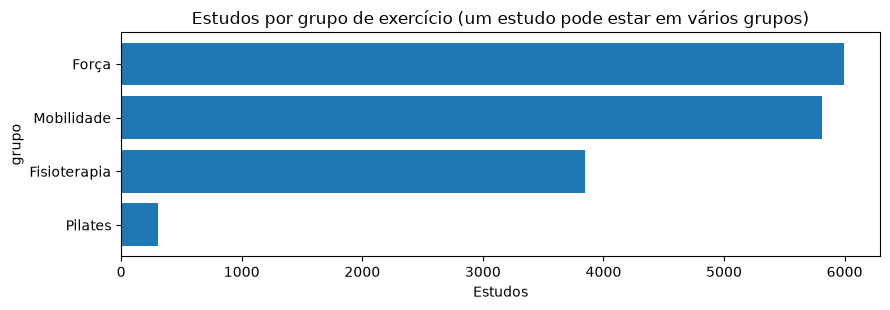

In [11]:
grupos = consultar(
    """
    SELECT unnest AS grupo, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(termos_encontrados)
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
grupos["grupo"] = grupos["grupo"].map(ROTULOS_GRUPO).fillna(grupos["grupo"])
barras(
    grupos,
    "Estudos por grupo de exercício (um estudo pode estar em vários grupos)",
    "Estudos",
)


## Enfermidades

O termo MeSH é o vocabulário controlado. O nome livre é o que o registro declarou em condições. Os dois cortes não se substituem.


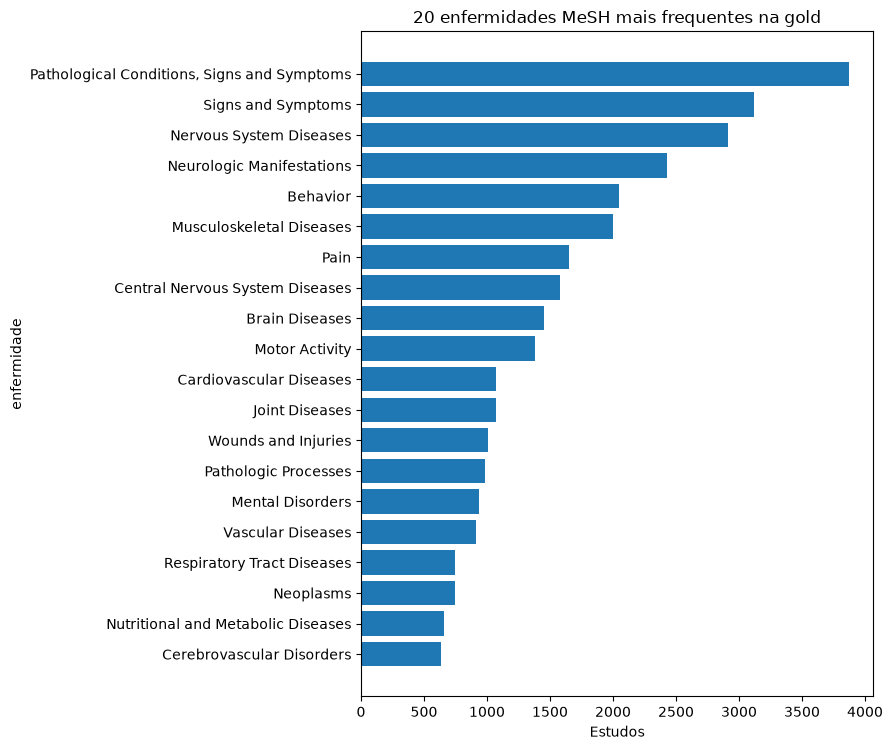

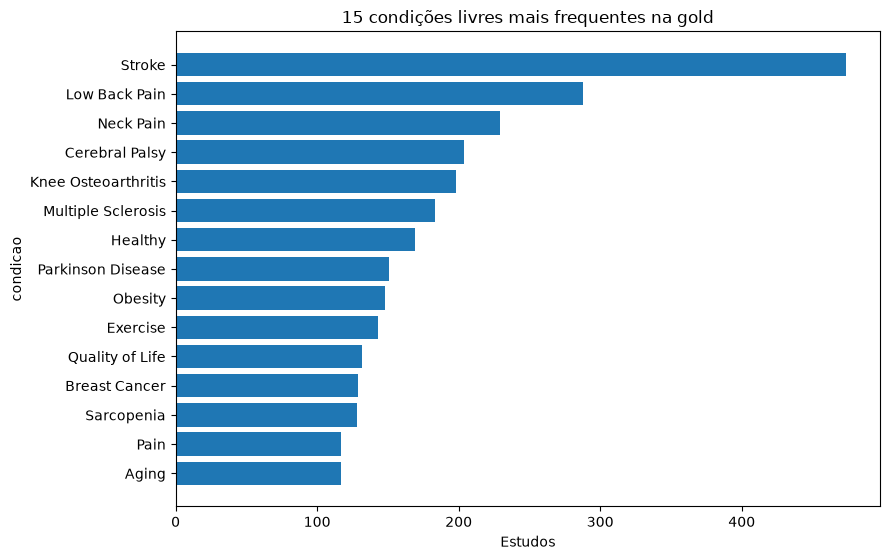

In [12]:
mesh = consultar(
    """
    SELECT unnest.mesh_term AS enfermidade, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(mesh_terms)
    WHERE unnest.mesh_term IS NOT NULL
    GROUP BY 1
    ORDER BY estudos DESC
    LIMIT 20
    """
)
barras(mesh, "20 enfermidades MeSH mais frequentes na gold", "Estudos")

condicoes = consultar(
    """
    SELECT unnest.name AS condicao, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(conditions)
    WHERE unnest.name IS NOT NULL
    GROUP BY 1
    ORDER BY estudos DESC
    LIMIT 15
    """
)
barras(condicoes, "15 condições livres mais frequentes na gold", "Estudos")


## Intervenções

O tipo separa exercício de fármaco, dispositivo ou procedimento quando o estudo tem mais de um braço. O nome é o rótulo declarado no ensaio.


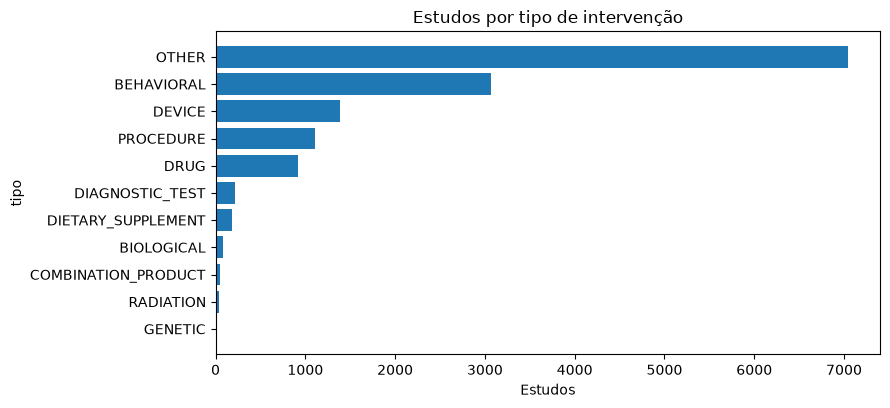

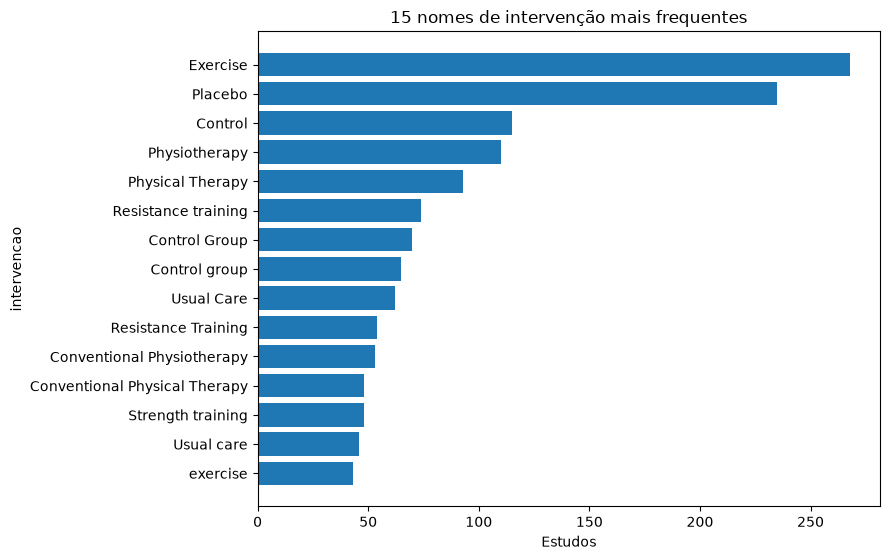

In [13]:
tipos = consultar(
    """
    SELECT unnest.intervention_type AS tipo, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(interventions)
    WHERE unnest.intervention_type IS NOT NULL
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
barras(tipos, "Estudos por tipo de intervenção", "Estudos")

nomes = consultar(
    """
    SELECT unnest.name AS intervencao, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(interventions)
    WHERE unnest.name IS NOT NULL
    GROUP BY 1
    ORDER BY estudos DESC
    LIMIT 15
    """
)
barras(nomes, "15 nomes de intervenção mais frequentes", "Estudos")


## Perfil do estudo

Tipo, fase, sexo e idade mínima descrevem quem o ensaio incluiu. O ano é o da data de conclusão. O país é o vigente, já sem os locais marcados como removidos.


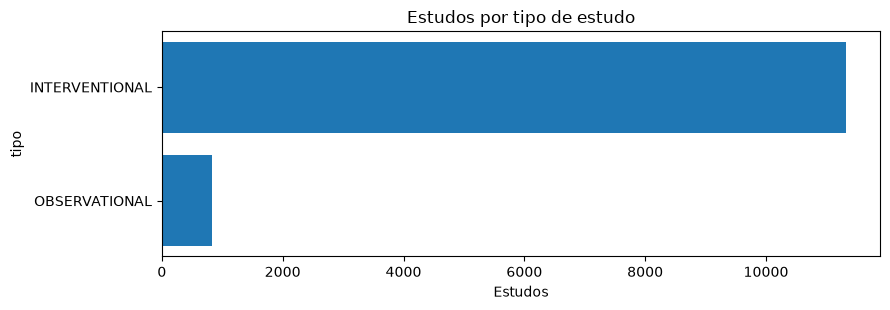

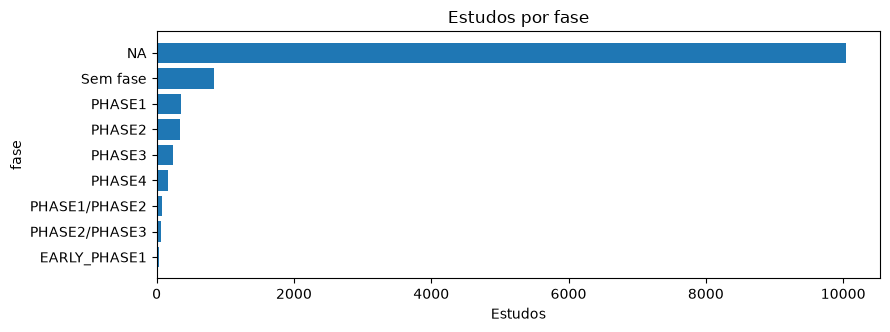

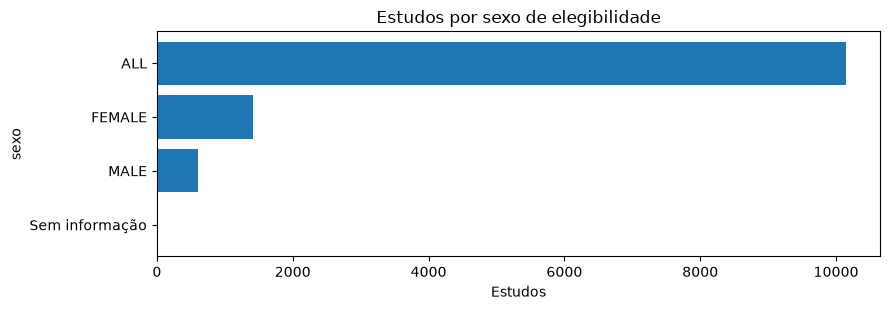

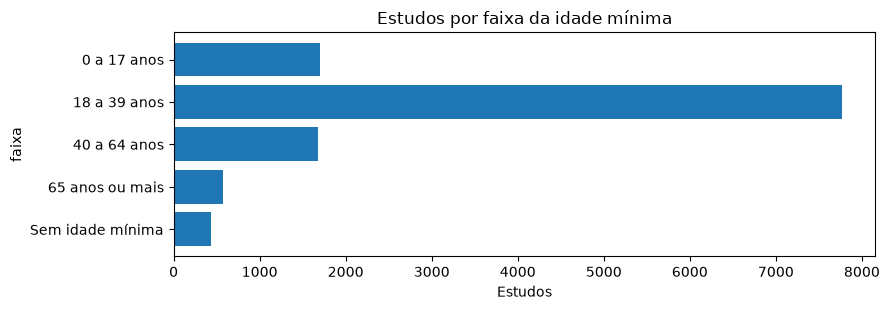

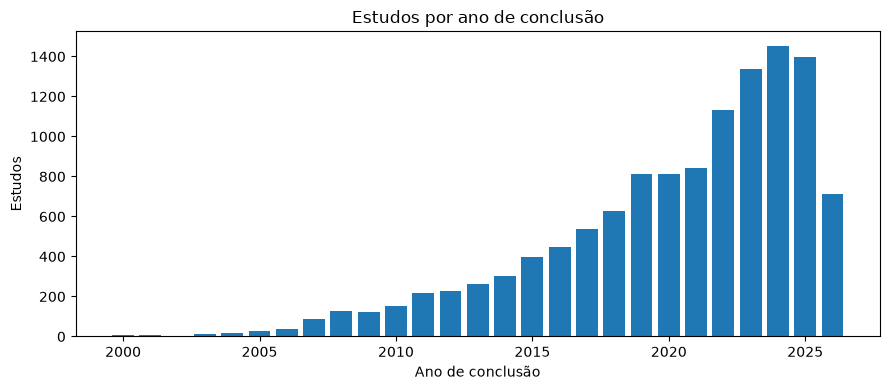

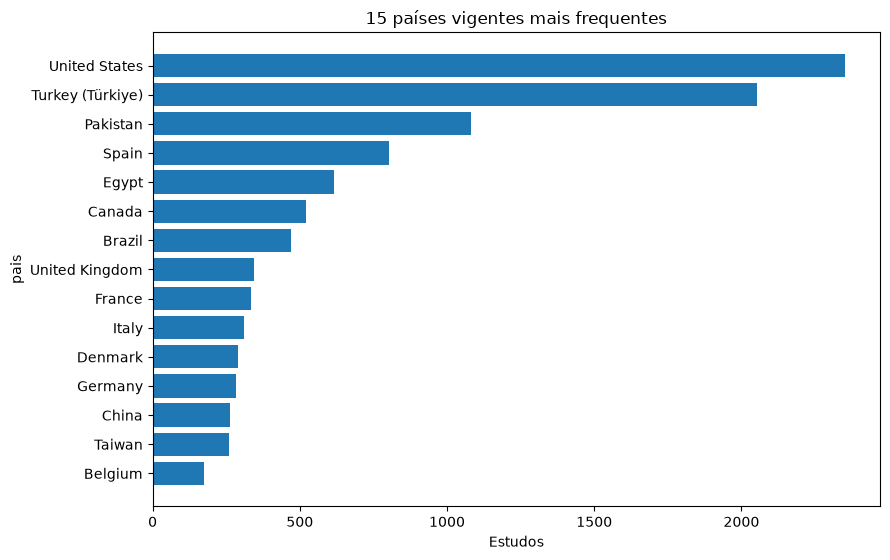

In [14]:
tipo_estudo = consultar(
    """
    SELECT coalesce(study_type, 'Sem informação') AS tipo, count(*) AS estudos
    FROM gold.estudos
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
barras(tipo_estudo, "Estudos por tipo de estudo", "Estudos")

fase = consultar(
    """
    SELECT coalesce(phase, 'Sem fase') AS fase, count(*) AS estudos
    FROM gold.estudos
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
barras(fase, "Estudos por fase", "Estudos")

sexo = consultar(
    """
    SELECT coalesce(gender, 'Sem informação') AS sexo, count(*) AS estudos
    FROM gold.estudos
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
barras(sexo, "Estudos por sexo de elegibilidade", "Estudos")

idade = consultar(
    """
    SELECT
        CASE
            WHEN minimum_age_years IS NULL THEN 'Sem idade mínima'
            WHEN minimum_age_years < 18 THEN '0 a 17 anos'
            WHEN minimum_age_years < 40 THEN '18 a 39 anos'
            WHEN minimum_age_years < 65 THEN '40 a 64 anos'
            ELSE '65 anos ou mais'
        END AS faixa,
        count(*) AS estudos
    FROM gold.estudos
    GROUP BY 1
    """
)
ordem_idade = [
    "0 a 17 anos",
    "18 a 39 anos",
    "40 a 64 anos",
    "65 anos ou mais",
    "Sem idade mínima",
]
idade["faixa"] = pd.Categorical(idade["faixa"], ordem_idade, ordered=True)
idade = idade.sort_values("faixa")
barras(idade, "Estudos por faixa da idade mínima", "Estudos")

anos = consultar(
    """
    SELECT year(completion_date) AS ano, count(*) AS estudos
    FROM gold.estudos
    WHERE completion_date IS NOT NULL
      AND year(completion_date) BETWEEN 1990 AND 2026
    GROUP BY 1
    ORDER BY 1
    """
)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(anos["ano"], anos["estudos"])
ax.set_title("Estudos por ano de conclusão")
ax.set_xlabel("Ano de conclusão")
ax.set_ylabel("Estudos")
fig.tight_layout()
plt.show()

paises = consultar(
    """
    SELECT unnest.name AS pais, count(DISTINCT nct_id) AS estudos
    FROM gold.estudos, unnest(countries_current)
    WHERE unnest.name IS NOT NULL
    GROUP BY 1
    ORDER BY estudos DESC
    LIMIT 15
    """
)
barras(paises, "15 países vigentes mais frequentes", "Estudos")


## Evidência publicada

Resultado publicado é a flag do próprio registro. A busca PubMed conta citações: um estudo pode ter várias, e citação sem PMID não tem resumo baixado.


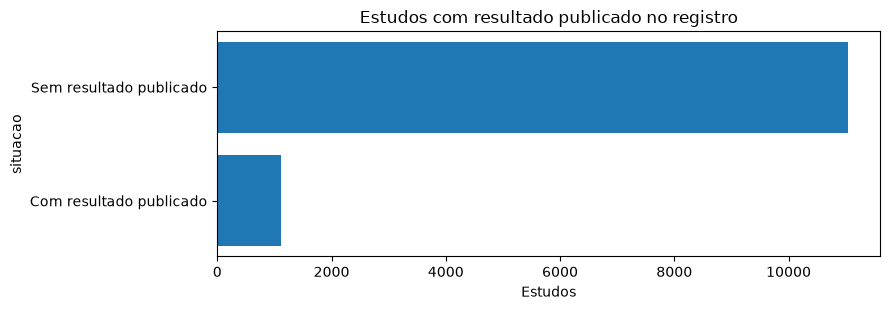

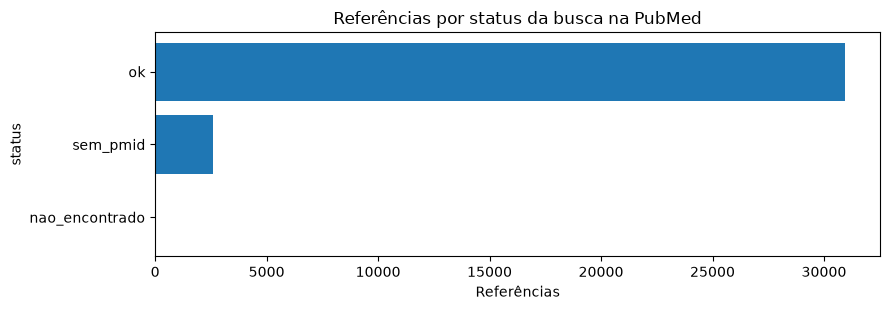

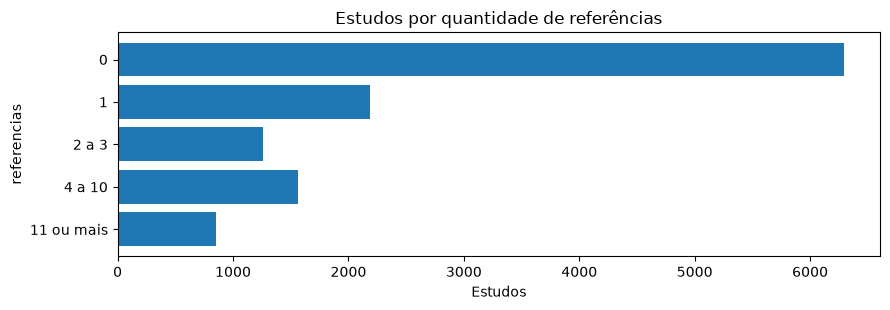

In [15]:
resultados = consultar(
    """
    SELECT
        CASE
            WHEN were_results_reported IS TRUE THEN 'Com resultado publicado'
            WHEN were_results_reported IS FALSE THEN 'Sem resultado publicado'
            ELSE 'Sem informação'
        END AS situacao,
        count(*) AS estudos
    FROM gold.estudos
    GROUP BY 1
    ORDER BY estudos DESC
    """
)
barras(resultados, "Estudos com resultado publicado no registro", "Estudos")

busca = consultar(
    """
    SELECT busca_status AS status, count(*) AS referencias
    FROM gold.referencias
    GROUP BY 1
    ORDER BY referencias DESC
    """
)
barras(busca, "Referências por status da busca na PubMed", "Referências")

faixas = consultar(
    """
    WITH por_estudo AS (
        SELECT g.nct_id, count(r.nct_id) AS referencias
        FROM gold.estudos AS g
        LEFT JOIN gold.referencias AS r ON r.nct_id = g.nct_id
        GROUP BY g.nct_id
    )
    SELECT
        CASE
            WHEN referencias = 0 THEN '0'
            WHEN referencias = 1 THEN '1'
            WHEN referencias BETWEEN 2 AND 3 THEN '2 a 3'
            WHEN referencias BETWEEN 4 AND 10 THEN '4 a 10'
            ELSE '11 ou mais'
        END AS referencias,
        count(*) AS estudos
    FROM por_estudo
    GROUP BY 1
    """
)
ordem_refs = ["0", "1", "2 a 3", "4 a 10", "11 ou mais"]
faixas["referencias"] = pd.Categorical(faixas["referencias"], ordem_refs, ordered=True)
faixas = faixas.sort_values("referencias")
barras(faixas, "Estudos por quantidade de referências", "Estudos")
